In [1]:
# 1.	Import the dataset from Kaggle (Chipotle.tsv).  

import pandas as pd

url = 'https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv'
chipo = pd.read_csv(url, sep='\t')
chipo.head(10)

,order_id,quantity,item_name,choice_description,item_price
0,1,1,Chips and Fresh Tomato Salsa,NaN,$2.39
1,1,1,Izze,[Clementine],$3.39
2,1,1,Nantucket Nectar,[Apple],$3.39
3,1,1,Chips and Tomatillo-Green Chili Salsa,NaN,$2.39
4,2,2,Chicken Bowl,"[Tomatillo-Red Chili Salsa (Hot), [Black Beans...",$16.98
5,3,1,Chicken Bowl,"[Fresh Tomato Salsa (Mild), [Rice, Cheese, Sou...",$10.98
6,3,1,Side of Chips,NaN,$1.69
7,4,1,Steak Burrito,"[Tomatillo Red Chili Salsa, [Fajita Vegetables...",$11.75
8,4,1,Steak Soft Tacos,"[Tomatillo Green Chili Salsa, [Pinto Beans, Ch...",$9.25
9,5,1,Steak Burrito,"[Fresh Tomato Salsa, [Rice, Black Beans, Pinto...",$9.25


In [10]:
# 2.	Which was the most ordered item? 

# Group by item_name and sum the quantity
item_quantity = chipo.groupby('item_name')['quantity'].sum().sort_values(ascending=False)

# Most ordered item
most_ordered_item = item_quantity.head(1)

print(most_ordered_item)


item_name
Chicken Bowl    761
Name: quantity, dtype: int64


In [11]:
# 3.	How much was the revenue for the period in the dataset? 

# Remove the dollar sign and convert to float
chipo['item_price'] = chipo['item_price'].str.replace('$', '', regex=False).astype(float)

# Calculate revenue for each order line
chipo['revenue'] = chipo['quantity'] * chipo['item_price']

# Total revenue
total_revenue = chipo['revenue'].sum()

print(f"Total revenue: ${total_revenue:.2f}")


Total revenue: $39237.02


In [12]:
# 4.	How many orders were made in the period? 

total_orders = chipo['order_id'].nunique()
print(f"Total number of orders: {total_orders}")


Total number of orders: 1834


In [13]:
# 5.	How many different items are sold? 

unique_items = chipo['item_name'].nunique()
print(f"Number of different items sold: {unique_items}")


Number of different items sold: 50


In [15]:
# 6.	What is the price of each item? (print a data frame with only two columns item_name and item_price) 

# Convert item_price to string first, then clean and convert to float
chipo['item_price'] = chipo['item_price'].astype(str).str.replace('$', '', regex=False).astype(float)

item_prices = chipo.groupby('item_name')['item_price'].min().reset_index()
print(item_prices)


                                item_name  item_price
0                       6 Pack Soft Drink        6.49
1                           Barbacoa Bowl        8.69
2                        Barbacoa Burrito        8.69
3                   Barbacoa Crispy Tacos        8.99
4                     Barbacoa Salad Bowl        9.39
5                     Barbacoa Soft Tacos        8.99
6                           Bottled Water        1.09
7                                    Bowl        7.40
8                                 Burrito        7.40
9                             Canned Soda        1.09
10                      Canned Soft Drink        1.25
11                          Carnitas Bowl        8.99
12                       Carnitas Burrito        8.69
13                  Carnitas Crispy Tacos        8.99
14                         Carnitas Salad        8.99
15                    Carnitas Salad Bowl        9.39
16                    Carnitas Soft Tacos        8.99
17                          

In [16]:
# 7.	Sort by the name of the item 

# Sort by item_name alphabetically
item_prices_sorted = item_prices.sort_values(by='item_name').reset_index(drop=True)

print(item_prices_sorted)


                                item_name  item_price
0                       6 Pack Soft Drink        6.49
1                           Barbacoa Bowl        8.69
2                        Barbacoa Burrito        8.69
3                   Barbacoa Crispy Tacos        8.99
4                     Barbacoa Salad Bowl        9.39
5                     Barbacoa Soft Tacos        8.99
6                           Bottled Water        1.09
7                                    Bowl        7.40
8                                 Burrito        7.40
9                             Canned Soda        1.09
10                      Canned Soft Drink        1.25
11                          Carnitas Bowl        8.99
12                       Carnitas Burrito        8.69
13                  Carnitas Crispy Tacos        8.99
14                         Carnitas Salad        8.99
15                    Carnitas Salad Bowl        9.39
16                    Carnitas Soft Tacos        8.99
17                          

In [17]:
# 8.	How many times were a Veggie Salad Bowl ordered? 

veggie_salad_orders = chipo.loc[chipo['item_name'] == 'Veggie Salad Bowl', 'quantity'].sum()
print(f'Veggie Salad Bowl was ordered {veggie_salad_orders} times.')


Veggie Salad Bowl was ordered 18 times.


In [18]:
# 9.	How many times people orderd more than one Canned Soda? 

# Filter rows where item is 'Canned Soda' and quantity > 1
multiple_canned_soda_orders = chipo[(chipo['item_name'] == 'Canned Soda') & (chipo['quantity'] > 1)]

# Count how many such orders exist
count_multiple_canned_soda = multiple_canned_soda_orders.shape[0]

print(f"Number of times people ordered more than one Canned Soda: {count_multiple_canned_soda}")


Number of times people ordered more than one Canned Soda: 20


C:\Users\yadav\AppData\Local\Temp\ipykernel_12916\3027456888.py:16: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  order_price = chipo.groupby('order_id').apply(lambda x: (x['quantity'] * x['item_price']).sum()).reset_index(name='total_price')


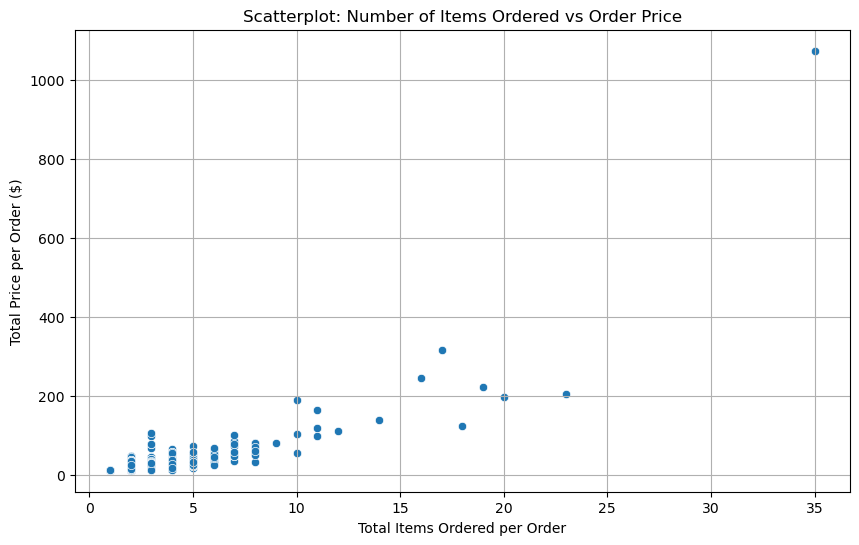

In [19]:
# 10.	Create a scatterplot with the number of items orderered per order price 

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load the dataset (if not already loaded)
url = 'https://raw.githubusercontent.com/justmarkham/DAT8/master/data/chipotle.tsv'
chipo = pd.read_csv(url, sep='\t')

# Clean item_price column if needed
if chipo['item_price'].dtype != 'float64':
    chipo['item_price'] = chipo['item_price'].astype(str).str.replace('$', '', regex=False).astype(float)

# Calculate total price per order
order_price = chipo.groupby('order_id').apply(lambda x: (x['quantity'] * x['item_price']).sum()).reset_index(name='total_price')

# Calculate total items ordered per order
order_items = chipo.groupby('order_id')['quantity'].sum().reset_index(name='total_items')

# Merge the two dataframes on order_id
order_summary = pd.merge(order_price, order_items, on='order_id')

# Plot scatterplot
plt.figure(figsize=(10,6))
sns.scatterplot(data=order_summary, x='total_items', y='total_price')
plt.title('Scatterplot: Number of Items Ordered vs Order Price')
plt.xlabel('Total Items Ordered per Order')
plt.ylabel('Total Price per Order ($)')
plt.grid(True)
plt.show()


In [34]:
# 11.	Import the dataset from attached file (u.user) 

import pandas as pd

url = 'https://raw.githubusercontent.com/justmarkham/DAT8/master/data/u.user'

occupation = pd.read_csv(url, sep='\t')
occupation.head(10)



,user_id|age|gender|occupation|zip_code
0,1|24|M|technician|85711
1,2|53|F|other|94043
2,3|23|M|writer|32067
3,4|24|M|technician|43537
4,5|33|F|other|15213
5,6|42|M|executive|98101
6,7|57|M|administrator|91344
7,8|36|M|administrator|05201
8,9|29|M|student|01002
9,10|53|M|lawyer|90703


In [43]:
# 12.	From the above dataset, discover what is the mean age per occupation

import pandas as pd

# Column names based on u.user dataset
column_names = ['user_id', 'age', 'gender', 'occupation', 'zip_code']

# Load data from the GitHub URL
url = 'https://raw.githubusercontent.com/justmarkham/DAT8/master/data/u.user'

# Read dataset
df = pd.read_csv(url, sep='|', names=column_names)

# Make sure 'age' is numeric
df['age'] = pd.to_numeric(df['age'], errors='coerce')

# Group by occupation and calculate mean age
mean_age_per_occupation = df.groupby('occupation')['age'].mean()

# Show result
print("Mean age per occupation:\n")
print(mean_age_per_occupation)



Mean age per occupation:

occupation
administrator    38.746835
artist           31.392857
doctor           43.571429
educator         42.010526
engineer         36.388060
entertainment    29.222222
executive        38.718750
healthcare       41.562500
homemaker        32.571429
lawyer           36.750000
librarian        40.000000
marketing        37.615385
none             26.555556
occupation             NaN
other            34.523810
programmer       33.121212
retired          63.071429
salesman         35.666667
scientist        35.548387
student          22.081633
technician       33.148148
writer           36.311111
Name: age, dtype: float64


In [44]:
# 13.	Discover the Male ratio per occupation and sort it from the most to the least 

# Create a new column to mark if the user is male
df['is_male'] = df['gender'] == 'M'

# Group by occupation and calculate the mean of the is_male column
# This gives the ratio of males per occupation
male_ratio = df.groupby('occupation')['is_male'].mean()

# Sort the male ratios in descending order
male_ratio_sorted = male_ratio.sort_values(ascending=False)

# Show the result
print("Male ratio per occupation (from most to least):\n")
print(male_ratio_sorted)


Male ratio per occupation (from most to least):

occupation
doctor           1.000000
engineer         0.970149
technician       0.962963
retired          0.928571
programmer       0.909091
executive        0.906250
scientist        0.903226
entertainment    0.888889
lawyer           0.833333
salesman         0.750000
educator         0.726316
student          0.693878
other            0.657143
marketing        0.615385
writer           0.577778
none             0.555556
administrator    0.544304
artist           0.535714
librarian        0.431373
healthcare       0.312500
homemaker        0.142857
occupation       0.000000
Name: is_male, dtype: float64


In [45]:
# 14.	Create a data dictionary 

# Step 1: Create the dictionary
raw_data = {
    "name": ['Bulbasaur', 'Charmander', 'Squirtle', 'Caterpie'],
    "evolution": ['Ivysaur', 'Charmeleon', 'Wartortle', 'Metapod'],
    "type": ['grass', 'fire', 'water', 'bug'],
    "hp": [45, 39, 44, 45],
    "pokedex": ['yes', 'no', 'yes', 'no']
}

# Optional Step 2: Convert to DataFrame
import pandas as pd
df_pokemon = pd.DataFrame(raw_data)

# Step 3: Display the DataFrame
print(df_pokemon)


         name   evolution   type  hp pokedex
0   Bulbasaur     Ivysaur  grass  45     yes
1  Charmander  Charmeleon   fire  39      no
2    Squirtle   Wartortle  water  44     yes
3    Caterpie     Metapod    bug  45      no


In [47]:
# 15.	Create a dataframe from the above dictionary 

import pandas as pd

# Define the data dictionary
raw_data = {
    "name": ['Bulbasaur', 'Charmander', 'Squirtle', 'Caterpie'],
    "evolution": ['Ivysaur', 'Charmeleon', 'Wartortle', 'Metapod'],
    "type": ['grass', 'fire', 'water', 'bug'],
    "hp": [45, 39, 44, 45],
    "pokedex": ['yes', 'no', 'yes', 'no']
}

# Create a DataFrame from the dictionary
df_pokemon = pd.DataFrame(raw_data)

# Display the DataFrame
print(df_pokemon)


         name   evolution   type  hp pokedex
0   Bulbasaur     Ivysaur  grass  45     yes
1  Charmander  Charmeleon   fire  39      no
2    Squirtle   Wartortle  water  44     yes
3    Caterpie     Metapod    bug  45      no


In [48]:
# 16.	Add another column called place, and insert what you have in mind. 

# Assuming df_pokemon is already created

# Add the new column 'place' with values of your choice
df_pokemon['place'] = ['Pallet Town', 'Cinnabar Island', 'Cerulean City', 'Viridian Forest']

# Display the updated DataFrame
print(df_pokemon)


         name   evolution   type  hp pokedex            place
0   Bulbasaur     Ivysaur  grass  45     yes      Pallet Town
1  Charmander  Charmeleon   fire  39      no  Cinnabar Island
2    Squirtle   Wartortle  water  44     yes    Cerulean City
3    Caterpie     Metapod    bug  45      no  Viridian Forest


In [52]:
# 17.	Import the dataset from Kaggle (iris.data) 

import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"
df_iris = pd.read_csv(url, header=None, names=column_names)

print(df_iris.head())


   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


In [51]:
# 18.	Create columns for the dataset ('sepal_length','sepal_width', 'petal_length', 'petal_width', 'class') 

import pandas as pd

# URL to the Iris dataset (UCI Machine Learning Repository)
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/iris/iris.data"

# Define the column names
column_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width', 'class']

# Load the dataset directly from the URL with assigned columns
df_iris = pd.read_csv(url, header=None, names=column_names)

# Show the first few rows to confirm
print(df_iris.head())


   sepal_length  sepal_width  petal_length  petal_width        class
0           5.1          3.5           1.4          0.2  Iris-setosa
1           4.9          3.0           1.4          0.2  Iris-setosa
2           4.7          3.2           1.3          0.2  Iris-setosa
3           4.6          3.1           1.5          0.2  Iris-setosa
4           5.0          3.6           1.4          0.2  Iris-setosa


In [53]:
# 19.	Is there any missing value in the dataframe? 

# Check for missing values in each column
missing_values = df_iris.isnull().sum()

print("Missing values per column:\n")
print(missing_values)


Missing values per column:

sepal_length    0
sepal_width     0
petal_length    0
petal_width     0
class           0
dtype: int64


In [54]:
print("Any missing values in dataset?", df_iris.isnull().values.any())


Any missing values in dataset? False


In [ ]:
# 20.	Let’s set the values of the rows 10 to 29 of the column 'petal_length' to NaN 

import numpy as np

# Set rows 10 to 29 (inclusive) of 'petal_length' to NaN
df_iris.loc[10:29, 'petal_length'] = np.nan

# Check that the values were set to NaN
print(df_iris.loc[10:29, 'petal_length'])


10   NaN
11   NaN
12   NaN
13   NaN
14   NaN
15   NaN
16   NaN
17   NaN
18   NaN
19   NaN
20   NaN
21   NaN
22   NaN
23   NaN
24   NaN
25   NaN
26   NaN
27   NaN
28   NaN
29   NaN
Name: petal_length, dtype: float64


In [56]:
# 21.	Now let’s substitute the NaN values to 1.0 

# Replace NaN values in 'petal_length' with 1.0
df_iris['petal_length'] = df_iris['petal_length'].fillna(1.0)

# Verify the substitution
print(df_iris.loc[10:29, 'petal_length'])


10    1.0
11    1.0
12    1.0
13    1.0
14    1.0
15    1.0
16    1.0
17    1.0
18    1.0
19    1.0
20    1.0
21    1.0
22    1.0
23    1.0
24    1.0
25    1.0
26    1.0
27    1.0
28    1.0
29    1.0
Name: petal_length, dtype: float64


In [57]:
# 22.	Now let's delete the column class 

# Delete the 'class' column
df_iris = df_iris.drop(columns=['class'])

# Verify the column is deleted
print(df_iris.head())


   sepal_length  sepal_width  petal_length  petal_width
0           5.1          3.5           1.4          0.2
1           4.9          3.0           1.4          0.2
2           4.7          3.2           1.3          0.2
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2


In [58]:
# 23.	Set the first 3 rows as NaN 

import numpy as np

# Set the first 3 rows to NaN for all columns
df_iris.iloc[0:3] = np.nan

# Verify the change
print(df_iris.head())


   sepal_length  sepal_width  petal_length  petal_width
0           NaN          NaN           NaN          NaN
1           NaN          NaN           NaN          NaN
2           NaN          NaN           NaN          NaN
3           4.6          3.1           1.5          0.2
4           5.0          3.6           1.4          0.2
